# IA no Cerrado: classificando folhas saudáveis e com sintomas

Notebook de demonstração da oficina **IA no Cerrado** (RIABIA-pro).

Vamos treinar uma rede neural para separar fotos de folhas em duas classes, **saudável** e **com sintomas**, e fazer uma pergunta científica simples:

> Um modelo treinado com fotos de **laboratório** continua acertando quando vê fotos tiradas **no campo**?

**Dados (abertos):**
- **PlantVillage** (Hughes & Salathé, 2015), cerca de 54 mil fotos de folhas sobre fundo uniforme. Licença CC BY-SA 3.0.
- **PlantDoc** (Singh et al., 2020), cerca de 2,6 mil fotos de folhas em condições reais. Licença CC BY 4.0.

**Roteiro:**
1. Preparar o ambiente e baixar os dados
2. Juntar as classes originais em “saudável” e “com sintomas”
3. Olhar os dados (laboratório × campo)
4. Treinar o **Modelo A** só com fotos de laboratório
5. Testar no laboratório e no campo
6. Treinar o **Modelo B** com fotos de laboratório + campo e comparar
7. Ver **onde o modelo olha** (Grad-CAM)
8. Testar com as suas próprias fotos

> No Colab, ative a GPU em *Ambiente de execução › Alterar o tipo de ambiente de execução › GPU*.

## 1. Preparar o ambiente

In [1]:
import os, random, pathlib, subprocess, shutil, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             f1_score, confusion_matrix)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

print("TensorFlow", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "nenhuma (vai funcionar, mas mais devagar)")

TensorFlow 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Configurações
Ajuste aqui. Para a demonstração ao vivo, `MAX_POR_CLASSE_PV = 300` e `EPOCAS = 5` rodam em poucos minutos na GPU.
Para o experimento completo (pôster), use `MAX_POR_CLASSE_PV = None` (todas as fotos) e mais épocas.

In [2]:
DADOS = pathlib.Path("dados")          # onde os datasets são baixados
FIGURAS = pathlib.Path("figuras")      # figuras prontas para slides e pôster
RESULTADOS = pathlib.Path("resultados")
for p in (DADOS, FIGURAS, RESULTADOS):
    p.mkdir(exist_ok=True)

TAMANHO = 224              # as imagens são redimensionadas para 224 × 224 pixels
LOTE = 32                  # quantas imagens o modelo vê por passo
EPOCAS = 8                 # máximo de épocas (o treino para antes se parar de melhorar)
MAX_POR_CLASSE_PV = None    # fotos por classe original do PlantVillage; None = todas
AJUSTE_FINO = True         # destravar as últimas camadas da rede depois do treino inicial
EPOCAS_AJUSTE = 3
PESOS = "imagenet"         # modelo pré-treinado (aprendizado por transferência)

CLASSES = ["saudável", "com sintomas"]   # rótulo 0 e rótulo 1

## 2. Baixar os dados

In [3]:
def executar(cmd, cwd=None):
    print("$", " ".join(cmd))
    subprocess.run(cmd, cwd=cwd, check=True)

PV_DIR = DADOS / "plantvillage"
PD_DIR = DADOS / "plantdoc"

# PlantVillage: baixamos só a pasta de fotos coloridas (raw/color)
if not (PV_DIR / "raw" / "color").exists():
    executar(["git", "clone", "--depth", "1", "--filter=blob:none", "--sparse",
              "https://github.com/spMohanty/PlantVillage-Dataset.git", str(PV_DIR)])
    executar(["git", "sparse-checkout", "set", "raw/color"], cwd=PV_DIR)

# PlantDoc: repositório completo (já vem separado em train/ e test/)
if not (PD_DIR / "train").exists():
    executar(["git", "clone", "--depth", "1",
              "https://github.com/pratikkayal/PlantDoc-Dataset.git", str(PD_DIR)])

print("Pronto.")

$ git clone --depth 1 --filter=blob:none --sparse https://github.com/spMohanty/PlantVillage-Dataset.git dados/plantvillage
$ git sparse-checkout set raw/color
$ git clone --depth 1 https://github.com/pratikkayal/PlantDoc-Dataset.git dados/plantdoc
Pronto.


## 3. De 38 classes para 2: saudável × com sintomas

Os datasets originais separam por espécie e doença (por exemplo, *Corn Common Rust*). Para a oficina, juntamos tudo em duas classes:
- **saudável (0):** pastas de folhas sadias
- **com sintomas (1):** doenças, pragas e danos

Usamos o termo “com sintomas” porque nem todo dano visível é doença.

In [4]:
EXTENSOES = {".jpg", ".jpeg", ".png", ".bmp"}

def listar(raiz, rotular, fonte, split=None):
    linhas = []
    for pasta in sorted(p for p in pathlib.Path(raiz).iterdir() if p.is_dir()):
        rotulo = rotular(pasta.name)
        if rotulo is None:
            continue
        for f in sorted(pasta.iterdir()):
            if f.suffix.lower() in EXTENSOES:
                linhas.append({"caminho": str(f), "classe_original": pasta.name,
                               "rotulo": rotulo, "fonte": fonte, "split": split})
    return pd.DataFrame(linhas)

def rotulo_plantvillage(nome):
    n = nome.lower()
    if "background" in n:
        return None
    return 0 if n.endswith("healthy") else 1

# No PlantDoc, as pastas sadias têm só o nome da planta + "leaf"
SAUDAVEIS_PLANTDOC = {"Apple leaf", "Bell_pepper leaf", "Blueberry leaf", "Cherry leaf",
                      "Peach leaf", "Raspberry leaf", "Soyabean leaf", "Strawberry leaf",
                      "Tomato leaf", "grape leaf"}

def rotulo_plantdoc(nome):
    return 0 if nome in SAUDAVEIS_PLANTDOC else 1

pv = listar(PV_DIR / "raw" / "color", rotulo_plantvillage, "PlantVillage (laboratório)")
pd_treino = listar(PD_DIR / "train", rotulo_plantdoc, "PlantDoc (campo)", "treino")
pd_teste = listar(PD_DIR / "test", rotulo_plantdoc, "PlantDoc (campo)", "teste")

if MAX_POR_CLASSE_PV:
    pv = (pv.sample(frac=1, random_state=SEED)
            .groupby("classe_original").head(MAX_POR_CLASSE_PV)
            .reset_index(drop=True))

for nome, df in [("PlantVillage", pv), ("PlantDoc treino", pd_treino), ("PlantDoc teste", pd_teste)]:
    c = df.rotulo.value_counts().reindex([0, 1], fill_value=0)
    print(f"{nome:16s} {len(df):6d} fotos | saudável: {c[0]:5d} | com sintomas: {c[1]:5d}")

PlantVillage      54305 fotos | saudável: 15084 | com sintomas: 39221
PlantDoc treino    2342 fotos | saudável:   760 | com sintomas:  1582
PlantDoc teste      236 fotos | saudável:    90 | com sintomas:   146


### Limpeza das fotos de campo
Algumas fotos do PlantDoc vêm em formatos que o TensorFlow não lê direto. Convertemos todas para JPEG e descartamos as que não abrem.

In [5]:
CACHE_PD = DADOS / "plantdoc_limpo"

def limpar(df):
    novos, descartadas = [], 0
    for _, linha in df.iterrows():
        destino = CACHE_PD / linha.split / linha.classe_original / (pathlib.Path(linha.caminho).stem + ".jpg")
        if not destino.exists():
            try:
                destino.parent.mkdir(parents=True, exist_ok=True)
                with Image.open(linha.caminho) as im:
                    im = im.convert("RGB")
                    im.thumbnail((512, 512))
                    im.save(destino, "JPEG", quality=92)
            except Exception:
                descartadas += 1
                continue
        novos.append({**linha.to_dict(), "caminho": str(destino)})
    print(f"{len(novos)} fotos prontas, {descartadas} descartadas")
    return pd.DataFrame(novos)

pd_treino = limpar(pd_treino)
pd_teste = limpar(pd_teste)

2342 fotos prontas, 0 descartadas
236 fotos prontas, 0 descartadas


## 4. Olhando os dados: laboratório × campo

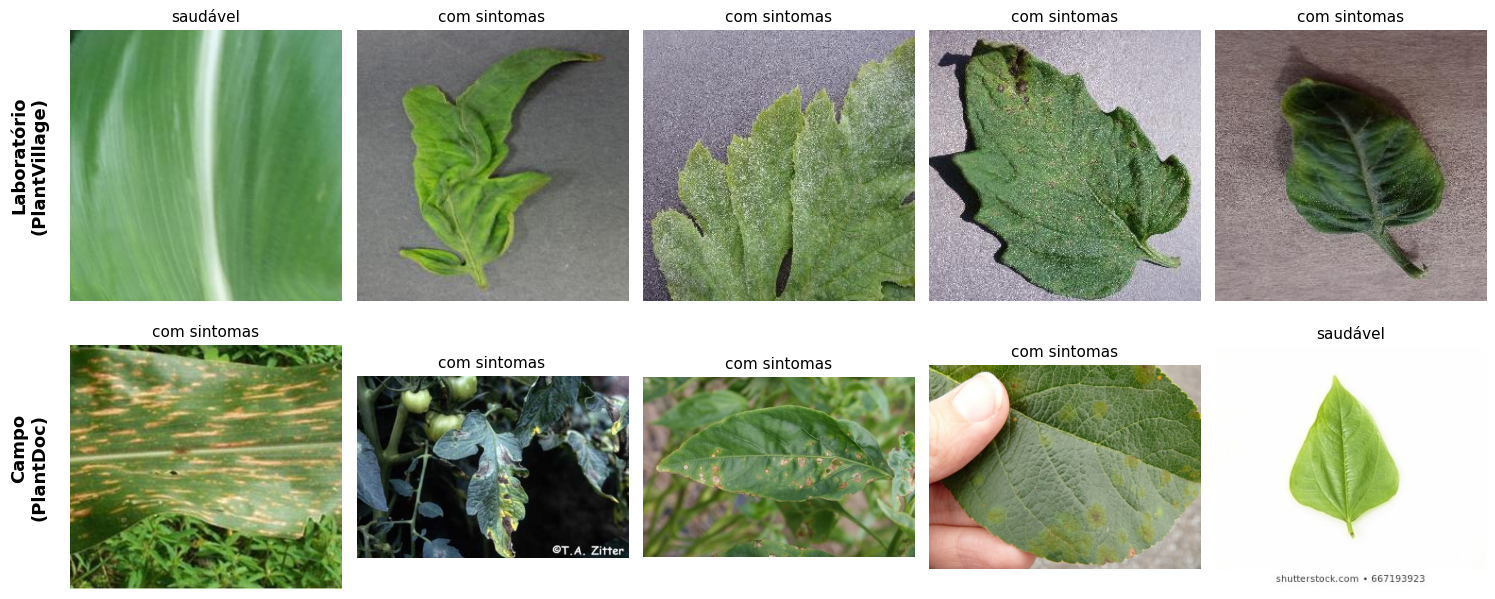

In [6]:
def grade(dfs_titulos, n=5, arquivo=None):
    fig, eixos = plt.subplots(len(dfs_titulos), n, figsize=(3 * n, 3.2 * len(dfs_titulos)))
    for i, (df, titulo) in enumerate(dfs_titulos):
        amostra = df.sample(n, random_state=SEED)
        for j, (_, linha) in enumerate(amostra.iterrows()):
            ax = eixos[i, j]
            ax.imshow(Image.open(linha.caminho).convert("RGB"))
            ax.set_title(CLASSES[linha.rotulo], fontsize=11)
            ax.axis("off")
        eixos[i, 0].text(-0.08, 0.5, titulo, transform=eixos[i, 0].transAxes,
                         rotation=90, va="center", ha="right", fontsize=13, fontweight="bold")
    plt.tight_layout()
    if arquivo:
        plt.savefig(FIGURAS / arquivo, dpi=300, bbox_inches="tight")
    plt.show()

grade([(pv, "Laboratório\n(PlantVillage)"), (pd_teste, "Campo\n(PlantDoc)")],
      arquivo="01_laboratorio_vs_campo.png")

**Pergunta para a turma:** o que muda entre as duas linhas de fotos? (Fundo, luz, quantidade de folhas por foto, outras coisas aparecendo…)

## 5. Separar treino, validação e teste
- **Treino (70%)**: o modelo aprende com estas fotos.
- **Validação (15%)**: usamos para decidir quando parar de treinar.
- **Teste (15%)**: só no final, para medir o desempenho em fotos que o modelo nunca viu.

In [7]:
pv_treino, pv_resto = train_test_split(pv, test_size=0.30, stratify=pv.classe_original, random_state=SEED)
pv_val, pv_teste = train_test_split(pv_resto, test_size=0.50, stratify=pv_resto.classe_original, random_state=SEED)
print(f"PlantVillage → treino {len(pv_treino)}, validação {len(pv_val)}, teste {len(pv_teste)}")

AUTOTUNE = tf.data.AUTOTUNE
aumento = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
], name="aumento_de_dados")

def carregar(caminho, rotulo):
    img = tf.io.read_file(caminho)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (TAMANHO, TAMANHO))
    return img, rotulo

def preprocessar(img):
    return tf.keras.applications.mobilenet_v2.preprocess_input(img)

def preparar(df, treino=False):
    ds = tf.data.Dataset.from_tensor_slices((df.caminho.values, df.rotulo.values.astype("float32")))
    if treino:
        ds = ds.shuffle(len(df), seed=SEED)
    ds = ds.map(carregar, num_parallel_calls=AUTOTUNE)
    if treino:
        ds = ds.map(lambda x, y: (aumento(x, training=True), y), num_parallel_calls=AUTOTUNE)
    ds = ds.map(lambda x, y: (preprocessar(x), y), num_parallel_calls=AUTOTUNE)
    return ds.batch(LOTE).prefetch(AUTOTUNE)

def pesos_das_classes(df):
    contagem = df.rotulo.value_counts()
    total = len(df)
    return {int(k): total / (2 * v) for k, v in contagem.items()}

PlantVillage → treino 38013, validação 8146, teste 8146


## 6. O modelo: aprendizado por transferência

Usamos a **MobileNetV2**, uma rede neural já treinada com mais de um milhão de imagens do ImageNet. Ela já sabe reconhecer bordas, texturas e formas. Só trocamos a parte final para responder a nossa pergunta: *saudável ou com sintomas?*

É a mesma ideia do Teachable Machine que vamos usar na oficina.

In [8]:
def criar_modelo():
    base = tf.keras.applications.MobileNetV2(input_shape=(TAMANHO, TAMANHO, 3),
                                             include_top=False, weights=PESOS)
    base.trainable = False
    x = tf.keras.layers.GlobalAveragePooling2D()(base.output)
    x = tf.keras.layers.Dropout(0.3)(x)
    saida = tf.keras.layers.Dense(1, activation="sigmoid", name="com_sintomas")(x)
    modelo = tf.keras.Model(base.input, saida)
    modelo.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                   loss="binary_crossentropy", metrics=["accuracy"])
    return modelo

def treinar(df_treino, df_val, nome):
    modelo = criar_modelo()
    ds_tr, ds_val = preparar(df_treino, treino=True), preparar(df_val)
    parar = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
    hist = modelo.fit(ds_tr, validation_data=ds_val, epochs=EPOCAS,
                      class_weight=pesos_das_classes(df_treino), callbacks=[parar])
    historico = pd.DataFrame(hist.history)
    if AJUSTE_FINO:
        # destrava as últimas camadas, mantendo as de normalização congeladas
        for camada in modelo.layers[-40:]:
            if not isinstance(camada, tf.keras.layers.BatchNormalization):
                camada.trainable = True
        modelo.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
                       loss="binary_crossentropy", metrics=["accuracy"])
        hist2 = modelo.fit(ds_tr, validation_data=ds_val, epochs=EPOCAS_AJUSTE,
                           class_weight=pesos_das_classes(df_treino), callbacks=[parar])
        historico = pd.concat([historico, pd.DataFrame(hist2.history)], ignore_index=True)
    historico.to_csv(RESULTADOS / f"historico_{nome}.csv", index_label="epoca")
    return modelo, historico

def plotar_historico(historico, titulo, arquivo):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].plot(historico.accuracy, label="treino"); ax[0].plot(historico.val_accuracy, label="validação")
    ax[0].set_title("Acurácia"); ax[0].set_xlabel("época"); ax[0].legend()
    ax[1].plot(historico.loss, label="treino"); ax[1].plot(historico.val_loss, label="validação")
    ax[1].set_title("Erro (loss)"); ax[1].set_xlabel("época"); ax[1].legend()
    fig.suptitle(titulo); plt.tight_layout()
    plt.savefig(FIGURAS / arquivo, dpi=300, bbox_inches="tight"); plt.show()

### Modelo A: treinado só com fotos de laboratório

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 409s 333ms/step - accuracy: 0.9192 - loss: 0.1972 - val_accuracy: 0.9488 - val_loss: 0.1349
Epoch 2/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 398s 335ms/step - accuracy: 0.9457 - loss: 0.1348 - val_accuracy: 0.9554 - val_loss: 0.1153
Epoch 3/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 386s 325ms/step - accuracy: 0.9508 - loss: 0.1241 - val_accuracy: 0.9452 - val_loss: 0.1387
Epoch 4/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 385s 324ms/step - accuracy: 0.9512 - loss: 0.1219 - val_accuracy: 0.9591 - val_loss: 0.1074
Epoch 5/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 446s 328ms/step - accuracy: 0.9531 - loss: 0.1187 - val_accuracy: 0.9344 - val_loss: 0.1539
Epoch 6/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 396s 333ms/step - accuracy: 0.9522 - loss: 0.1210 - val_accuracy: 0.9612 - val_loss: 0.1041
Epoch 7/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 436s 328ms/step - accuracy: 0.9539 - loss: 0.1182 - val_accuracy: 0.9477 - val_loss: 0.1323
Epoch 8/8
1188/1188 

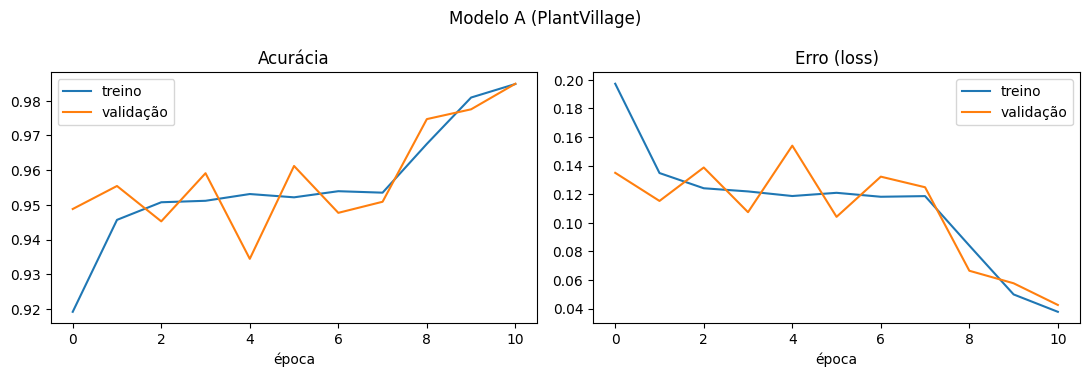

In [9]:
modelo_A, hist_A = treinar(pv_treino, pv_val, "modelo_A")
plotar_historico(hist_A, "Modelo A (PlantVillage)", "02_treino_modelo_A.png")

## 7. Avaliação: laboratório × campo
Medimos:
- **Acurácia:** porcentagem de acertos.
- **Acurácia balanceada:** média dos acertos em cada classe (justa quando uma classe tem mais fotos).
- **F1 (com sintomas):** equilíbrio entre encontrar as folhas com sintomas e não dar alarme falso.

,cenário,n_fotos,acurácia,acurácia_balanceada,f1_com_sintomas
0,Modelo A · teste laboratório,8146,0.981,0.986,0.987
1,Modelo A · teste campo,236,0.856,0.824,0.892


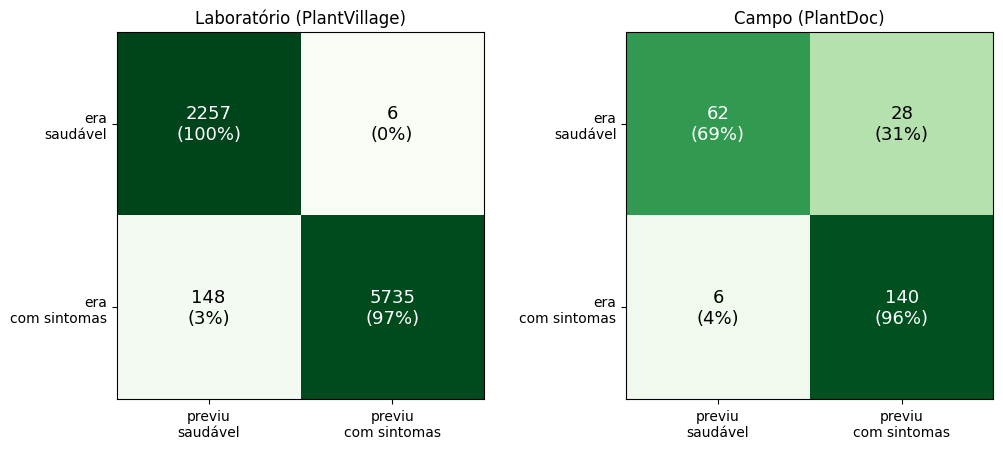

In [10]:
def avaliar(modelo, df, cenario):
    prob = modelo.predict(preparar(df), verbose=0).ravel()
    pred = (prob >= 0.5).astype(int)
    y = df.rotulo.values
    metricas = {"cenário": cenario, "n_fotos": len(y),
                "acurácia": accuracy_score(y, pred),
                "acurácia_balanceada": balanced_accuracy_score(y, pred),
                "f1_com_sintomas": f1_score(y, pred, zero_division=0)}
    return metricas, confusion_matrix(y, pred, labels=[0, 1])

def plotar_matrizes(itens, arquivo):
    fig, eixos = plt.subplots(1, len(itens), figsize=(5.2 * len(itens), 4.6))
    eixos = np.atleast_1d(eixos)
    for ax, (titulo, cm) in zip(eixos, itens):
        perc = cm / cm.sum(axis=1, keepdims=True)
        ax.imshow(perc, cmap="Greens", vmin=0, vmax=1)
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{cm[i, j]}\n({perc[i, j]:.0%})", ha="center", va="center",
                        fontsize=13, color="white" if perc[i, j] > 0.5 else "black")
        ax.set_xticks([0, 1], [f"previu\n{c}" for c in CLASSES])
        ax.set_yticks([0, 1], [f"era\n{c}" for c in CLASSES])
        ax.set_title(titulo, fontsize=12)
    plt.tight_layout(); plt.savefig(FIGURAS / arquivo, dpi=300, bbox_inches="tight"); plt.show()

m_lab, cm_lab = avaliar(modelo_A, pv_teste, "Modelo A · teste laboratório")
m_campo, cm_campo = avaliar(modelo_A, pd_teste, "Modelo A · teste campo")
display(pd.DataFrame([m_lab, m_campo]).round(3))
plotar_matrizes([("Laboratório (PlantVillage)", cm_lab), ("Campo (PlantDoc)", cm_campo)],
                "03_matrizes_modelo_A.png")

**Para discutir:** se a acurácia cai muito no campo, o modelo aprendeu detalhes das fotos de laboratório (fundo, luz, enquadramento) que não existem no mundo real. Isso é **viés nos dados**, o mesmo fenômeno do desafio “Tentem enganar o modelo”.

## 8. Modelo B: e se o treino tiver fotos de campo também?
Juntamos ao treino as fotos da pasta `train` do PlantDoc. O teste de campo continua sendo a pasta `test`, que o modelo nunca viu.

Epoch 1/8
1251/1251 ━━━━━━━━━━━━━━━━━━━━ 426s 333ms/step - accuracy: 0.9075 - loss: 0.2225 - val_accuracy: 0.9527 - val_loss: 0.1321
Epoch 2/8
1251/1251 ━━━━━━━━━━━━━━━━━━━━ 409s 327ms/step - accuracy: 0.9372 - loss: 0.1584 - val_accuracy: 0.9569 - val_loss: 0.1203
Epoch 3/8
1251/1251 ━━━━━━━━━━━━━━━━━━━━ 408s 326ms/step - accuracy: 0.9406 - loss: 0.1500 - val_accuracy: 0.9343 - val_loss: 0.1606
Epoch 4/8
1251/1251 ━━━━━━━━━━━━━━━━━━━━ 405s 324ms/step - accuracy: 0.9413 - loss: 0.1475 - val_accuracy: 0.9579 - val_loss: 0.1110
Epoch 5/8
1251/1251 ━━━━━━━━━━━━━━━━━━━━ 411s 328ms/step - accuracy: 0.9440 - loss: 0.1433 - val_accuracy: 0.9505 - val_loss: 0.1293
Epoch 6/8
1251/1251 ━━━━━━━━━━━━━━━━━━━━ 410s 328ms/step - accuracy: 0.9442 - loss: 0.1453 - val_accuracy: 0.9506 - val_loss: 0.1233
Epoch 1/3
1251/1251 ━━━━━━━━━━━━━━━━━━━━ 543s 425ms/step - accuracy: 0.9594 - loss: 0.1037 - val_accuracy: 0.9725 - val_loss: 0.0733
Epoch 2/3
1251/1251 ━━━━━━━━━━━━━━━━━━━━ 419s 334ms/step - accuracy: 

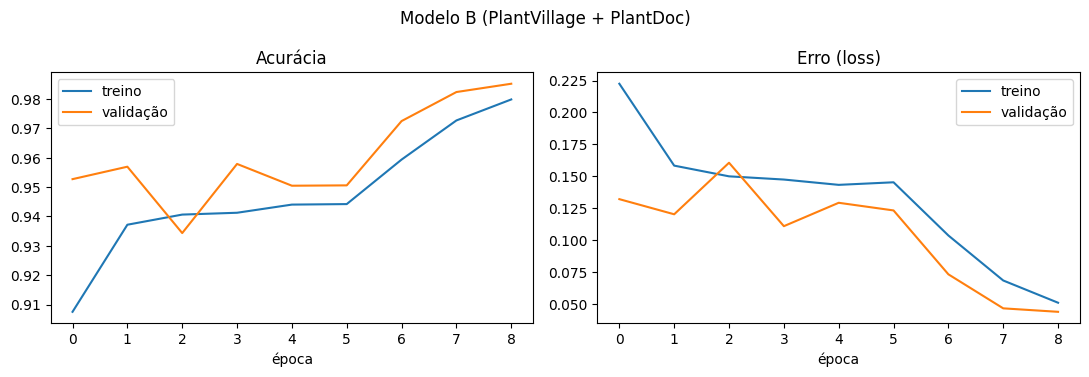

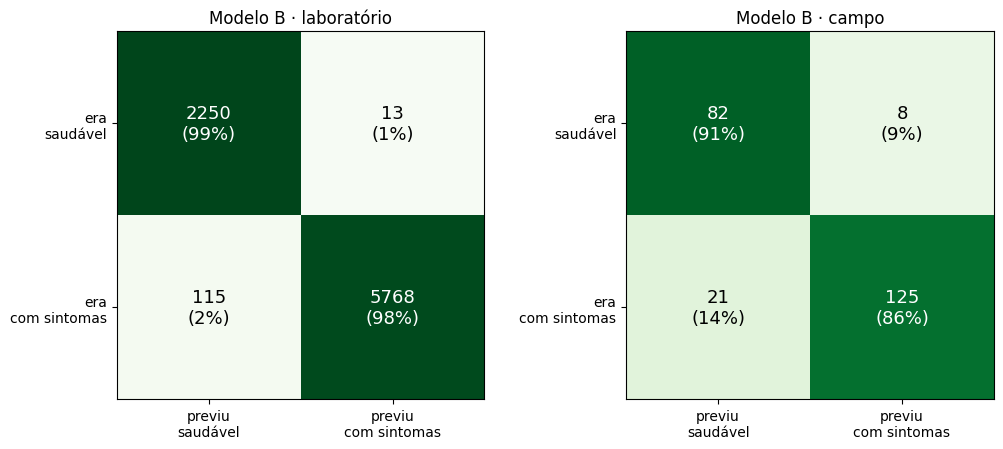

In [11]:
pd_tr, pd_val = train_test_split(pd_treino, test_size=0.15, stratify=pd_treino.rotulo, random_state=SEED)
treino_B = pd.concat([pv_treino, pd_tr], ignore_index=True)
val_B = pd.concat([pv_val, pd_val], ignore_index=True)

modelo_B, hist_B = treinar(treino_B, val_B, "modelo_B")
plotar_historico(hist_B, "Modelo B (PlantVillage + PlantDoc)", "04_treino_modelo_B.png")

mB_lab, cmB_lab = avaliar(modelo_B, pv_teste, "Modelo B · teste laboratório")
mB_campo, cmB_campo = avaliar(modelo_B, pd_teste, "Modelo B · teste campo")
plotar_matrizes([("Modelo B · laboratório", cmB_lab), ("Modelo B · campo", cmB_campo)],
                "05_matrizes_modelo_B.png")

### Resumo dos resultados

,cenário,n_fotos,acurácia,acurácia_balanceada,f1_com_sintomas
0,Modelo A · teste laboratório,8146,0.981,0.986,0.987
1,Modelo A · teste campo,236,0.856,0.824,0.892
2,Modelo B · teste laboratório,8146,0.984,0.987,0.989
3,Modelo B · teste campo,236,0.877,0.884,0.896


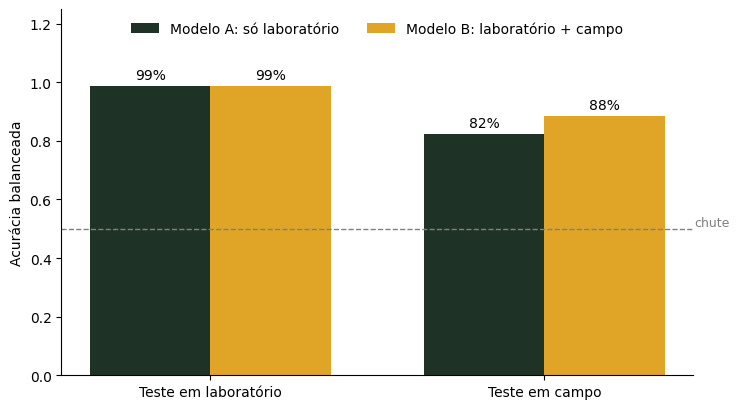

In [12]:
resultados = pd.DataFrame([m_lab, m_campo, mB_lab, mB_campo])
resultados.to_csv(RESULTADOS / "resultados.csv", index=False)
display(resultados.round(3))

fig, ax = plt.subplots(figsize=(7.5, 4.2))
x = np.arange(2); larg = 0.36
a = [m_lab["acurácia_balanceada"], m_campo["acurácia_balanceada"]]
b = [mB_lab["acurácia_balanceada"], mB_campo["acurácia_balanceada"]]
barras_a = ax.bar(x - larg / 2, a, larg, label="Modelo A: só laboratório", color="#1E3326")
barras_b = ax.bar(x + larg / 2, b, larg, label="Modelo B: laboratório + campo", color="#E0A526")
for barras in (barras_a, barras_b):
    ax.bar_label(barras, labels=[f"{v:.0%}" for v in barras.datavalues], padding=3)
ax.set_xticks(x, ["Teste em laboratório", "Teste em campo"])
ax.set_ylim(0, 1.25); ax.set_ylabel("Acurácia balanceada")
ax.axhline(0.5, ls="--", lw=1, color="gray"); ax.text(1.45, 0.51, "chute", color="gray", fontsize=9)
ax.legend(loc="upper center", ncol=2, frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(FIGURAS / "06_comparacao_modelos.png", dpi=300, bbox_inches="tight"); plt.show()

## 9. Onde o modelo está olhando? (Grad-CAM)
O Grad-CAM pinta as regiões da imagem que mais pesaram na decisão. Se o modelo olha para o fundo e não para a folha, desconfie.

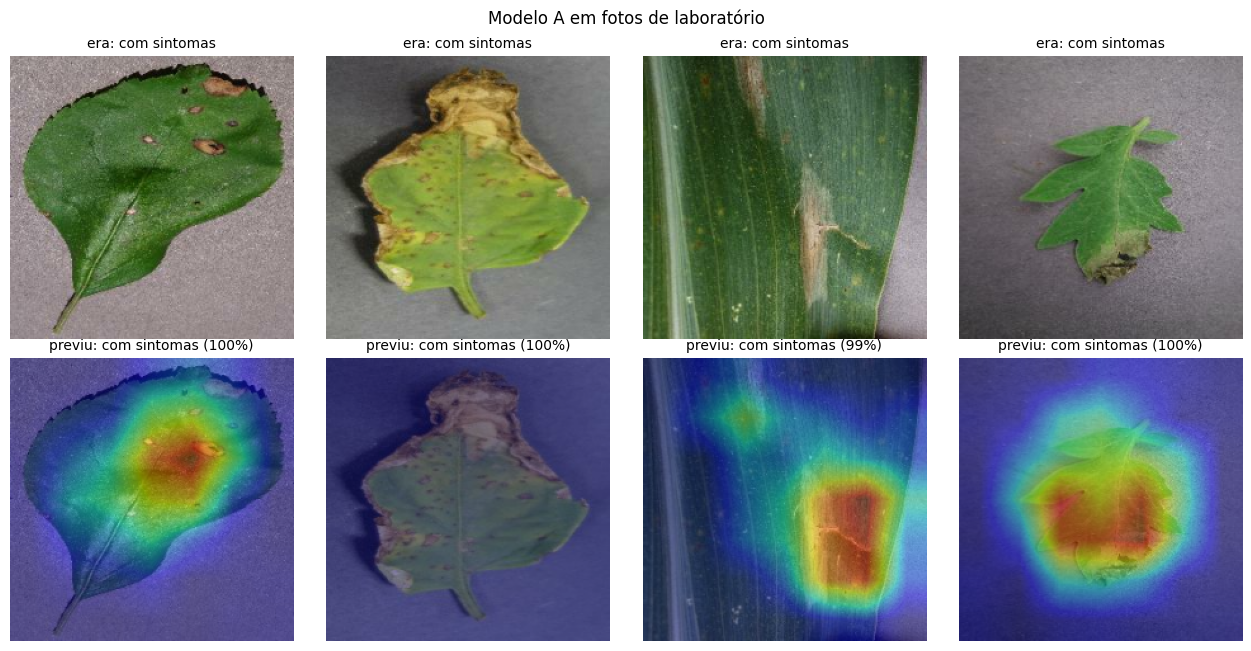

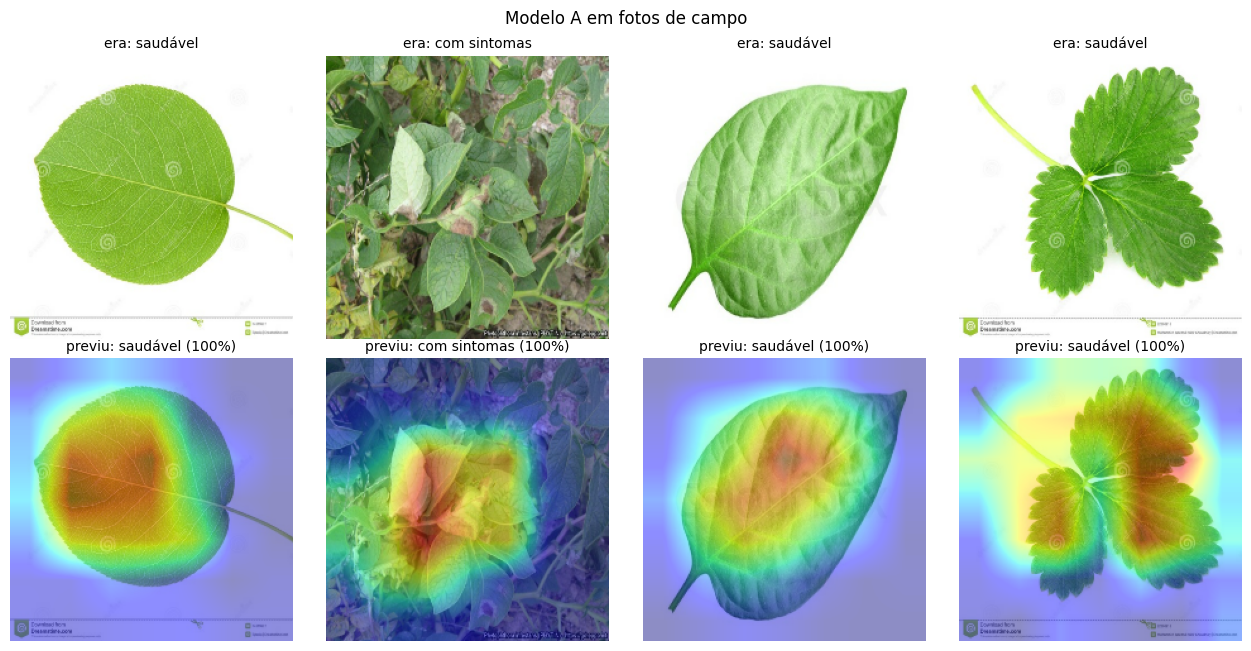

In [13]:
def gradcam(modelo, caminho, camada="out_relu"):
    img, _ = carregar(caminho, 0.0)
    entrada = preprocessar(img)[tf.newaxis, ...]
    modelo_grad = tf.keras.Model(modelo.inputs, [modelo.get_layer(camada).output, modelo.output])
    with tf.GradientTape() as fita:
        mapas, pred = modelo_grad(entrada)
        p = pred[:, 0]
        alvo = tf.where(p >= 0.5, p, 1.0 - p)      # explica a classe que o modelo escolheu
    grads = fita.gradient(alvo, mapas)
    pesos = tf.reduce_mean(grads, axis=(0, 1, 2))
    cam = tf.nn.relu(tf.reduce_sum(mapas[0] * pesos, axis=-1))
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    cam = tf.image.resize(cam[..., tf.newaxis], (TAMANHO, TAMANHO))[..., 0].numpy()
    return img.numpy().astype("uint8"), cam, float(p[0])

def mostrar_gradcam(modelo, df, n=4, titulo="", arquivo=None):
    amostra = df.sample(n, random_state=SEED + 1)
    fig, eixos = plt.subplots(2, n, figsize=(3.2 * n, 6.6))
    for j, (_, linha) in enumerate(amostra.iterrows()):
        img, cam, p = gradcam(modelo, linha.caminho)
        previsto = CLASSES[int(p >= 0.5)]
        eixos[0, j].imshow(img); eixos[0, j].axis("off")
        eixos[0, j].set_title(f"era: {CLASSES[linha.rotulo]}", fontsize=10)
        eixos[1, j].imshow(img); eixos[1, j].imshow(cam, cmap="jet", alpha=0.45); eixos[1, j].axis("off")
        eixos[1, j].set_title(f"previu: {previsto} ({max(p, 1 - p):.0%})", fontsize=10)
    fig.suptitle(titulo); plt.tight_layout()
    if arquivo:
        plt.savefig(FIGURAS / arquivo, dpi=300, bbox_inches="tight")
    plt.show()

mostrar_gradcam(modelo_A, pv_teste, titulo="Modelo A em fotos de laboratório", arquivo="07_gradcam_laboratorio.png")
mostrar_gradcam(modelo_A, pd_teste, titulo="Modelo A em fotos de campo", arquivo="08_gradcam_campo.png")

## 10. Teste com as suas fotos
Fotografe folhas do Cerrado (de preferência sozinhas, sobre fundo liso) e envie aqui. Lembre: o modelo foi treinado com plantas cultivadas, então folhas nativas são um teste de verdade da capacidade de generalizar.

In [14]:
MINHAS = pathlib.Path("minhas_fotos"); MINHAS.mkdir(exist_ok=True)
try:
    from google.colab import files
    for nome, conteudo in files.upload().items():
        (MINHAS / nome).write_bytes(conteudo)
except ImportError:
    print(f"Fora do Colab: coloque as fotos na pasta {MINHAS}/ e rode a próxima célula.")

In [15]:
fotos = sorted(f for f in MINHAS.iterdir() if f.suffix.lower() in EXTENSOES)
for f in fotos:
    img, cam, p = gradcam(modelo_B, str(f))
    fig, ax = plt.subplots(1, 2, figsize=(7, 3.6))
    ax[0].imshow(img); ax[0].axis("off"); ax[0].set_title(f.name, fontsize=9)
    ax[1].imshow(img); ax[1].imshow(cam, cmap="jet", alpha=0.45); ax[1].axis("off")
    ax[1].set_title(f"{CLASSES[int(p >= 0.5)]} ({max(p, 1 - p):.0%})")
    plt.tight_layout(); plt.show()
if not fotos:
    print("Nenhuma foto encontrada.")

Nenhuma foto encontrada.


## 11. Salvar modelos e resumo

In [16]:
modelo_A.save(RESULTADOS / "modelo_A.keras")
modelo_B.save(RESULTADOS / "modelo_B.keras")

resumo = {
    "configuracao": {"tamanho": TAMANHO, "epocas": EPOCAS, "max_por_classe_pv": MAX_POR_CLASSE_PV,
                     "ajuste_fino": AJUSTE_FINO, "semente": SEED},
    "n_fotos": {"pv_treino": len(pv_treino), "pv_teste": len(pv_teste),
                "pd_treino": len(pd_tr), "pd_teste": len(pd_teste)},
    "resultados": resultados.round(4).to_dict(orient="records"),
}
(RESULTADOS / "resumo.json").write_text(json.dumps(resumo, ensure_ascii=False, indent=2))
print(json.dumps(resumo, ensure_ascii=False, indent=2))

{
  "configuracao": {
    "tamanho": 224,
    "epocas": 8,
    "max_por_classe_pv": null,
    "ajuste_fino": true,
    "semente": 42
  },
  "n_fotos": {
    "pv_treino": 38013,
    "pv_teste": 8146,
    "pd_treino": 1990,
    "pd_teste": 236
  },
  "resultados": [
    {
      "cenário": "Modelo A · teste laboratório",
      "n_fotos": 8146,
      "acurácia": 0.9811,
      "acurácia_balanceada": 0.9861,
      "f1_com_sintomas": 0.9868
    },
    {
      "cenário": "Modelo A · teste campo",
      "n_fotos": 236,
      "acurácia": 0.8559,
      "acurácia_balanceada": 0.8239,
      "f1_com_sintomas": 0.8917
    },
    {
      "cenário": "Modelo B · teste laboratório",
      "n_fotos": 8146,
      "acurácia": 0.9843,
      "acurácia_balanceada": 0.9874,
      "f1_com_sintomas": 0.989
    },
    {
      "cenário": "Modelo B · teste campo",
      "n_fotos": 236,
      "acurácia": 0.8771,
      "acurácia_balanceada": 0.8836,
      "f1_com_sintomas": 0.8961
    }
  ]
}


---
**Créditos dos dados**
- Hughes, D. P.; Salathé, M. *An open access repository of images on plant health to enable the development of mobile disease diagnostics.* arXiv:1511.08060, 2015. Licença CC BY-SA 3.0.
- Singh, D. et al. *PlantDoc: A Dataset for Visual Plant Disease Detection.* CoDS-COMAD 2020. Licença CC BY 4.0.

**Observação de licença:** os autores do PlantVillage pedem que modelos treinados com os dados sejam compartilhados sob a mesma licença (CC BY-SA 3.0).

In [17]:
!zip -r ia_no_cerrado_saida.zip figuras resultados
from google.colab import files
files.download("ia_no_cerrado_saida.zip")

  adding: figuras/ (stored 0%)
  adding: figuras/05_matrizes_modelo_B.png (deflated 16%)
  adding: figuras/04_treino_modelo_B.png (deflated 12%)
  adding: figuras/08_gradcam_campo.png (deflated 6%)
  adding: figuras/02_treino_modelo_A.png (deflated 11%)
  adding: figuras/01_laboratorio_vs_campo.png (deflated 2%)
  adding: figuras/07_gradcam_laboratorio.png (deflated 6%)
  adding: figuras/06_comparacao_modelos.png (deflated 22%)
  adding: figuras/03_matrizes_modelo_A.png (deflated 16%)
  adding: resultados/ (stored 0%)
  adding: resultados/resumo.json (deflated 68%)
  adding: resultados/resultados.csv (deflated 43%)
  adding: resultados/historico_modelo_B.csv (deflated 48%)
  adding: resultados/modelo_B.keras (deflated 9%)
  adding: resultados/historico_modelo_A.csv (deflated 49%)
  adding: resultados/modelo_A.keras (deflated 9%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>